# Supplementary Figure S5c. TransMap-global versus ARCHIE

S-LDSC marginal τ*, heritability enrichment and joint τ* of the TransMap-global (leave-one-chromosome-out transCCA) and ARCHIE (LOCO) annotations; joint τ* is from a model with both annotations. Source: `Manu_Figures/Figure2.ipynb` cell 61 (input `transCCA_comparison/results/sLDSC_transCCA_ARCHIE_LOCO.rds`); bars are drawn as in that cell, with a dashed line at 0.

Error bars are estimate ± 1.9 × SE, exactly as in the source figure code (Figure2.ipynb uses 1.9, not 1.96; the caption's "95% confidence intervals" would be ± 1.96 × SE). Red asterisks mark nominal two-sided P < 0.05 with a positive estimate, again as in the source code; no multiple-testing correction is applied, although the caption says "FDR<5%". For reference the rds also has `fdr_bh`, a Benjamini–Hochberg adjustment across all tests of the same metric in this panel (not used for the stars). S-LDSC values are random-effects meta-analyses across traits (57 all, 18 brain, 22 blood; per-trait models conditional on the 53 baseline-LD annotations), recomputed here from the per-trait S-LDSC outputs; they match the summary rds read by the source notebook to machine precision. Enrichment P-values come from the h2-scaled enrichment statistic (author's `runSingleEnrMetaAnalysis`); the plotted estimate/SE is the meta-analysed S-LDSC Enrichment.

Input: `data/Figure_S5c_transmap_global_archie_sldsc.rds`.

In [1]:
library(ggplot2)
library(patchwork)
res <- readRDS("data/Figure_S5c_transmap_global_archie_sldsc.rds")
res

metric,trait_set,trait,method,annotation_raw,est,se,pvalue,fdr_bh,n_traits
<fct>,<chr>,<fct>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Marginal tau*,all_traits,All traits (57),TransMap-global,transCCA_LOCO,0.004572525,0.02438858,8.512794e-01,8.512794e-01,57
Marginal tau*,blood_traits,Blood-related traits (22),TransMap-global,transCCA_LOCO,-0.037739587,0.05198748,4.678779e-01,7.018169e-01,22
Marginal tau*,brain_traits,Brain-related traits (18),TransMap-global,transCCA_LOCO,0.034707917,0.04387318,4.288878e-01,7.018169e-01,18
Marginal tau*,all_traits,All traits (57),ARCHIE,ARCHIE_PMD_LOCO,-0.042614788,0.02115149,4.393173e-02,1.317952e-01,57
Marginal tau*,blood_traits,Blood-related traits (22),ARCHIE,ARCHIE_PMD_LOCO,-0.134601639,0.02990640,6.770958e-06,4.062575e-05,22
Marginal tau*,brain_traits,Brain-related traits (18),ARCHIE,ARCHIE_PMD_LOCO,-0.010247235,0.03905624,7.930352e-01,8.512794e-01,18
Enrichment,all_traits,All traits (57),TransMap-global,transCCA_LOCO,1.190733355,0.53509178,7.989841e-01,7.989841e-01,57
Enrichment,blood_traits,Blood-related traits (22),TransMap-global,transCCA_LOCO,0.297337308,1.13336691,2.004182e-01,3.320903e-01,22
Enrichment,brain_traits,Brain-related traits (18),TransMap-global,transCCA_LOCO,1.860727919,0.96946576,2.213935e-01,3.320903e-01,18


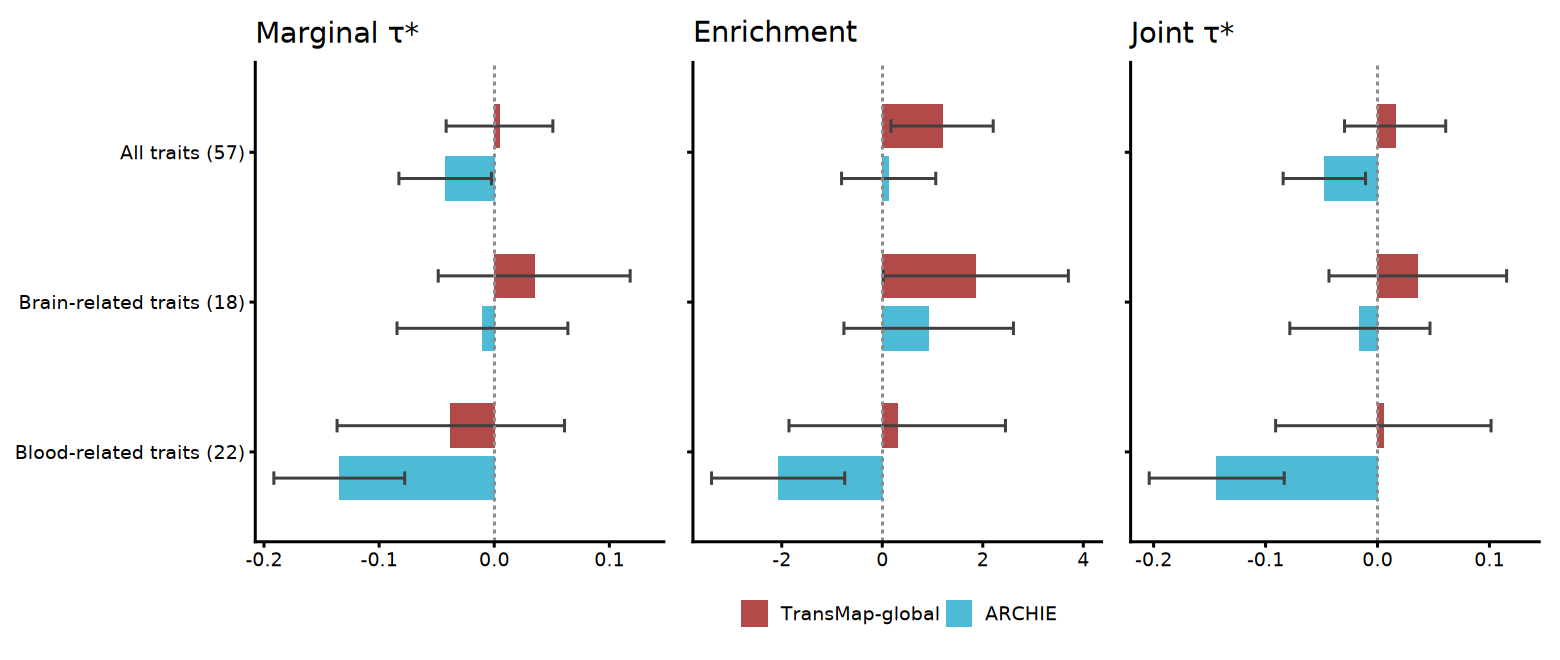

In [2]:
cols <- c("TransMap-global" = "#B24A4A", "ARCHIE" = "#4DBBD5")
res$trait <- factor(res$trait, levels = rev(levels(res$trait)))
res$method <- factor(res$method, levels = c("ARCHIE", "TransMap-global"))
res$star <- ifelse(res$pvalue < 0.05 & res$est > 0, "*", "")
bar <- function(m, ttl, show_y) {
  d <- subset(res, metric == m)
  p <- ggplot(d, aes(x = est, y = trait, fill = method)) +
    geom_col(position = position_dodge(width = 0.7), width = 0.58) +
    geom_errorbar(aes(xmin = est - 1.9 * se, xmax = est + 1.9 * se), orientation = "y",
                  position = position_dodge(width = 0.7), width = 0.18, colour = "grey25") +
    geom_text(aes(x = est + 2.2 * se, label = star), position = position_dodge(width = 0.7),
              colour = "#B2182B", size = 6, hjust = 0) +
    geom_vline(xintercept = 0, linetype = "dashed", colour = "grey55") +
    scale_fill_manual(values = cols, breaks = c("TransMap-global", "ARCHIE"), name = NULL) +
    labs(x = NULL, y = NULL, title = ttl) +
    theme_classic(base_size = 14) + theme(legend.position = "bottom")
  if (!show_y) p <- p + theme(axis.text.y = element_blank())
  p
}
options(repr.plot.width = 13, repr.plot.height = 5.5)
(bar("Marginal tau*", expression("Marginal " * tau * "*"), TRUE) | bar("Enrichment", "Enrichment", FALSE) |
   bar("Joint tau*", expression("Joint " * tau * "*"), FALSE)) + plot_layout(guides = "collect") &
  theme(legend.position = "bottom")